# M4 · GBLA: shared parameters plus private per-generator offsets

**Motivation from M3 (geometric, not curvature).** Pooled LN tuning is generator-dominated: in the span of the four single-generator solutions the weights are F2F 0.58, FS 0.27, DF 0.18, NT ≈ 0 (G_eff / G = 0.57). Training on FaceSwap alone beats the pooled model on unseen FaceShifter (video AUC 89.6 vs 88.2). NeuralTextures only works when pooled (72 alone → 94 pooled). The curvature formula that was supposed to explain this failed its own checks (asymmetric, step-size-dependent Hessians; negative regrets), so M4 does **not** use H_g or τ² = 1/(2λ). It tests the practical claim: private offsets let each generator keep what pooling would average away, and the shared part generalises better to an unseen generator.

**Method.** The deployed model is a shared vector θ_s (LayerNorms + head, P = 104,450). During training, a batch from generator g uses

θ_g = θ_s + δ_g

and the loss is M1's loss on that batch plus λ ‖δ_g‖². δ_g is discarded after training. Reals are assigned round-robin to the G generators (each real crop belongs to exactly one generator for the whole run), so each generator sees all of its fakes plus 1/G of the reals — the same share as in M1/M3. One epoch visits every generator once (900 steps, the same budget as one M1 epoch).

**What is compared** (10 epochs, FaceShifter never trained):

| run | what it is |
|---|---|
| λ = ∞ | δ_g forced to 0: pooled ERM with M4's data order. Must land near M1 epoch 10. |
| λ ∈ {1, 0.1, 0.01, 0.001, 0} | GBLA. λ = 0 is four independent models (sanity: FaceShifter should look like the best single-generator run). |

**Deployed** is always θ_s (104,450 numbers). Only θ_s is used at test time.

| Section | What it does | Run time |
|---|---|---|
| 1. Setup | settings, imports | seconds |
| 2. Data | crops in RAM, round-robin loader | ~1–8 min |
| 3. Model | detector, parameter report | ~1 min |
| 4. Training | λ sweep, resumable | ~1.3 h per λ, ~8 h for all 6 |
| 5. Evaluation | vs M1 and vs train-on-one, curves | ~10 min |
| 6. Send results back | push this notebook | – |

## 1. Setup

### 1.1 Settings

`LAMBDAS` is in priority order. `inf` is pooled ERM inside this code (δ = 0). Results go to `runs/m4/`.

In [1]:
# 1.1 Settings
import os
from pathlib import Path

DATA_ROOT = Path("/nlsasfs/home/isea/isea64/GBLA-Deepfake Detection")
FACES_ROOT = DATA_ROOT / "faces"
INDEX_CSV = DATA_ROOT / "index" / "ffpp_c23.csv"
RUNS_ROOT = DATA_ROOT / "runs"
M4_DIR = RUNS_ROOT / "m4"
M3_DIR = RUNS_ROOT / "m3"

ALL_GENERATORS = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures", "FaceShifter"]
TRAIN_GENERATORS = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures"]
SHORT = {"original": "real", "Deepfakes": "DF", "Face2Face": "F2F", "FaceSwap": "FS",
         "NeuralTextures": "NT", "FaceShifter": "FSh"}
G = len(TRAIN_GENERATORS)

ARCH, PRETRAINED = "ViT-L-14", "openai"
L2_NORM = True
W_UNIFORM, W_ALIGN = 0.5, 0.1
AUGMENT = True
BATCH_SIZE = 128
EPOCHS = 10
CYCLE_EPOCHS = 10
WARMUP_EPOCHS = 1
LR_MAX, LR_MIN = 3e-4, 1e-5
SEED = 0

# priority order. float("inf") = pooled ERM (deltas stay 0)
LAMBDAS = [float("inf"), 0.1, 0.01, 1.0, 0.001, 0.0]

M1_RUN_DIR = RUNS_ROOT / "m1" / f"lnclip_{ARCH}_train-{'-'.join(SHORT[g] for g in TRAIN_GENERATORS)}_seed{SEED}"
POOLED_EPOCH = 10

VAL_FRAMES_PER_VIDEO = 8
CACHE_IN_RAM = True
EVAL_BATCH = 256
GRAD_CHECKPOINTING = False

COMMON_CONFIG = {
    "arch": ARCH, "pretrained": PRETRAINED, "quick_gelu": True, "l2_norm": L2_NORM,
    "w_uniform": W_UNIFORM, "w_align": W_ALIGN, "augment": AUGMENT,
    "batch_size": BATCH_SIZE, "epochs": EPOCHS, "cycle_epochs": CYCLE_EPOCHS,
    "warmup_epochs": WARMUP_EPOCHS, "lr_max": LR_MAX, "lr_min": LR_MIN, "seed": SEED,
    "method": "GBLA: theta_g = theta_s + delta_g, penalty lambda * ||delta_g||^2",
    "reals": "round-robin, fixed for the run, 1/G per generator",
    "deployed": "theta_s only",
}
assert INDEX_CSV.exists(), f"index not found: {INDEX_CSV}"
assert (M1_RUN_DIR / f"epoch_{POOLED_EPOCH:02d}.pt").exists(), f"M1 checkpoint missing: {M1_RUN_DIR}"
M4_DIR.mkdir(parents=True, exist_ok=True)
print("M4 runs go to:", M4_DIR)
print("lambdas:", [("inf" if lam == float("inf") else lam) for lam in LAMBDAS])

M4 runs go to: /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m4
lambdas: ['inf', 0.1, 0.01, 1.0, 0.001, 0.0]


### 1.2 Imports and environment

`os.cpu_count()` reports the whole node (256), but the job may only use the CPUs in its affinity mask and cgroup quota; the loader uses that number. Free RAM decides in 2.2 how many crops can be kept in memory.

In [2]:
# 1.2 Imports and environment
import json, math, random, time
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
from torch.utils.data import DataLoader, Dataset, Sampler
from torchvision import tv_tensors
from torchvision.io import ImageReadMode, read_image
from torchvision.transforms import v2 as T
from tqdm.auto import tqdm

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
assert torch.cuda.is_available(), "M4 needs the GPU"
DEVICE = "cuda"


def usable_cpus():
    """CPUs this job may use: the affinity mask and the cgroup CPU quota."""
    n = len(os.sched_getaffinity(0))
    for quota_file, period_file in [("/sys/fs/cgroup/cpu.max", None),
                                    ("/sys/fs/cgroup/cpu/cpu.cfs_quota_us", "/sys/fs/cgroup/cpu/cpu.cfs_period_us")]:
        try:
            if period_file is None:
                quota, period = Path(quota_file).read_text().split()
            else:
                quota, period = Path(quota_file).read_text().strip(), Path(period_file).read_text().strip()
            if quota not in ("max", "-1"):
                n = min(n, max(1, int(quota) // int(period)))
        except (OSError, ValueError):
            pass
    return n


def available_memory_gb():
    """Free RAM for this job: the smaller of MemAvailable and the cgroup limit minus non-cache usage."""
    candidates = []
    try:
        meminfo = dict(line.split(":", 1) for line in Path("/proc/meminfo").read_text().splitlines())
        candidates.append(int(meminfo["MemAvailable"].split()[0]) * 1024)
    except (OSError, KeyError, ValueError):
        pass
    for limit_file, usage_file, stat_file, cache_key in [
            ("/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory.current", "/sys/fs/cgroup/memory.stat", "file"),
            ("/sys/fs/cgroup/memory/memory.limit_in_bytes", "/sys/fs/cgroup/memory/memory.usage_in_bytes",
             "/sys/fs/cgroup/memory/memory.stat", "cache")]:
        try:
            limit = Path(limit_file).read_text().strip()
            if not limit.isdigit() or int(limit) >= 1 << 60:
                continue
            usage = int(Path(usage_file).read_text().strip())
            stat = dict(line.split() for line in Path(stat_file).read_text().splitlines())
            candidates.append(int(limit) - usage + int(stat.get(cache_key, 0)))
        except (OSError, ValueError):
            pass
    return min(candidates) / 1e9 if candidates else 0.0


CPUS = usable_cpus()
NUM_WORKERS = max(1, min(16, CPUS - 1))     # one CPU stays with the training process
torch.set_num_threads(2)

pd.Series({
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "open_clip": open_clip.__version__,
    "GPU": torch.cuda.get_device_name(0),
    "CPU cores on the node": os.cpu_count(),
    "CPUs usable by this job": CPUS,
    "data loader workers": NUM_WORKERS,
    "free RAM for this job (GB)": round(available_memory_gb(), 1),
}, name="value").to_frame()

/nlsasfs/home/isea/isea64/venv_jupyter/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,value
torch,2.6.0+cu124
torchvision,0.21.0+cu124
open_clip,3.3.0
GPU,NVIDIA A100-SXM4-40GB
CPU cores on the node,256
CPUs usable by this job,16
data loader workers,15
free RAM for this job (GB),1052.1


## 2. Data

### 2.1 Index and subsets

Same splits as M1: train = real + the 4 training generators (115,200 crops); test = real + all 5 generators, FaceShifter unseen. Val keeps 8 evenly spaced frames of each video (5,600 crops instead of 22,400). Val only monitors training, so this changes no trained model; val numbers are therefore not identical to M1's.

In [3]:
# 2.1 Index and subsets
index = pd.read_csv(INDEX_CSV, dtype={"video_id": str, "target_id": str, "source_id": str},
                    keep_default_na=False)
CATEGORIES = ["original"] + ALL_GENERATORS
GEN_CODE = {g: k for k, g in enumerate(CATEGORIES)}


def subset(split, generators):
    keep = (index.split == split) & index.generator.isin(["original", *generators])
    return index[keep].reset_index(drop=True)


train_df = subset("train", TRAIN_GENERATORS)
val_all = subset("val", TRAIN_GENERATORS)
frames_per_video = int(val_all.groupby(["generator", "video_id"]).size().max())
keep_every = max(1, frames_per_video // VAL_FRAMES_PER_VIDEO)
frame_rank = val_all.groupby(["generator", "video_id"]).frame_idx.rank(method="first").astype(int) - 1
val_df = val_all[frame_rank % keep_every == 0].reset_index(drop=True)
test_df = subset("test", ALL_GENERATORS)

display(pd.DataFrame({name: df.groupby("generator").size().reindex(CATEGORIES)
                      for name, df in [("train", train_df), ("val (subsampled)", val_df), ("test", test_df)]}
                     ).fillna(0).astype(int))

,train,val (subsampled),test
generator,,,
original,23040,1120,4480
Deepfakes,23040,1120,4480
Face2Face,23040,1120,4480
FaceSwap,23040,1120,4480
NeuralTextures,23040,1120,4480
FaceShifter,0,0,4480


### 2.2 Decoded crops in RAM

Reading 115,200 small PNG files per epoch from the network file system was the likely M1 bottleneck. Here every crop is read once per session into one uint8 array (224 × 224 × 3 bytes per crop: train 17.3 GB, val 0.8 GB, test 4.0 GB), in the order train → val → test, as long as it fits in 60% of free RAM. Sets that don't fit are read from disk as in M1. Nothing is written to disk. The printed read speed also tells us how fast the file system is.

In [4]:
# 2.2 Decoded crops in RAM
def load_images(df, desc):
    """Decodes every crop of an index slice into one uint8 array (N, H, W, 3), using threads."""
    paths = [FACES_ROOT / p for p in df.path]
    first = np.asarray(Image.open(paths[0]).convert("RGB"))
    out = np.empty((len(paths), *first.shape), dtype=np.uint8)

    def work(k):
        out[k] = np.asarray(Image.open(paths[k]).convert("RGB"))

    with ThreadPoolExecutor(max_workers=min(32, 4 * CPUS)) as pool:
        list(tqdm(pool.map(work, range(len(paths))), total=len(paths), desc=desc, mininterval=5))
    return out


images = {}
budget = 0.6 * available_memory_gb()
for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    need = len(df) * 224 * 224 * 3 / 1e9
    if CACHE_IN_RAM and need <= budget:
        t = time.time()
        images[name] = load_images(df, f"{name} crops -> RAM")
        budget -= need
        sec = time.time() - t
        print(f"{name}: {len(df):,} crops, {need:.1f} GB in RAM, {sec / 60:.1f} min ({len(df) / sec:.0f} crops/s from disk)")
    else:
        images[name] = None
        print(f"{name}: read from disk during training (needs {need:.1f} GB, RAM budget left {budget:.1f} GB)")

train crops -> RAM: 100%|██████████| 115200/115200 [00:59<00:00, 1950.59it/s]


train: 115,200 crops, 17.3 GB in RAM, 1.0 min (1859 crops/s from disk)


val crops -> RAM: 100%|██████████| 5600/5600 [00:03<00:00, 1670.00it/s]


val: 5,600 crops, 0.8 GB in RAM, 0.1 min (1617 crops/s from disk)


test crops -> RAM: 100%|██████████| 26880/26880 [00:13<00:00, 1930.90it/s]

test: 26,880 crops, 4.0 GB in RAM, 0.2 min (1856 crops/s from disk)


### 2.3 Round-robin loader

Each training generator owns all of its fakes and a **fixed** 1/G slice of the training reals (round-robin by row order, seed 0). A real crop is never shared across generators, so Σ_g L_g is one pass over the M1 training set. One GBLA epoch = G blocks of 225 steps = 900 steps, the same number of images as one M1 epoch. Block order inside an epoch is shuffled by (seed, epoch); order inside a block depends only on (seed, generator, epoch).

In [5]:
# 2.3 Round-robin loader
CLIP_MEAN = (0.48145466, 0.4578275, 0.40821073)
CLIP_STD = (0.26862954, 0.26130258, 0.27577711)


def make_transform(train):
    steps = []
    if train and AUGMENT:
        steps += [
            T.RandomHorizontalFlip(0.5),
            T.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
            T.RandomApply([T.GaussianBlur(kernel_size=7, sigma=(0.1, 2.0))], p=0.1),
            T.ColorJitter(brightness=0.1, contrast=0.1),
            T.JPEG(quality=(40, 100)),
        ]
    steps += [T.ToDtype(torch.float32, scale=True), T.Normalize(CLIP_MEAN, CLIP_STD)]
    return T.Compose(steps)


class FaceDataset(Dataset):
    def __init__(self, df, train, images=None):
        self.paths = [str(FACES_ROOT / p) for p in df.path]
        self.images = images
        self.labels = torch.tensor(df.label.values, dtype=torch.long)
        self.gens = torch.tensor(df.generator.map(GEN_CODE).values, dtype=torch.long)
        self.transform = make_transform(train)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        if self.images is not None:
            image = torch.from_numpy(np.array(self.images[i])).permute(2, 0, 1)
        else:
            image = read_image(self.paths[i], mode=ImageReadMode.RGB)
        return self.transform(tv_tensors.Image(image)).as_subclass(torch.Tensor), self.labels[i], self.gens[i]


class RoundRobinSampler(Sampler):
    """One epoch = one block per training generator, in an order fixed by (seed, epoch)."""

    def __init__(self, df, seed):
        self.seed = seed
        self.epoch = 0
        gen = df.generator.values
        real_idx = np.flatnonzero(gen == "original")
        # fixed split: real row r goes to generator r % G
        self.blocks = {}
        for k, g in enumerate(TRAIN_GENERATORS):
            fakes = np.flatnonzero(gen == g)
            reals = real_idx[k::G][: len(fakes) // G]
            self.blocks[g] = (fakes, reals)
        self.n_per = len(self.blocks[TRAIN_GENERATORS[0]][0]) + len(self.blocks[TRAIN_GENERATORS[0]][1])

    def set_epoch(self, epoch):
        self.epoch = epoch

    def __iter__(self):
        order_rng = np.random.default_rng([self.seed, self.epoch, 1])
        gens = list(TRAIN_GENERATORS)
        order_rng.shuffle(gens)
        out = []
        for g in gens:
            fakes, reals = self.blocks[g]
            rng = np.random.default_rng([self.seed, ALL_GENERATORS.index(g), self.epoch])
            out.extend(rng.permutation(np.concatenate([fakes, reals])).tolist())
        return iter(out)

    def __len__(self):
        return self.n_per * G


train_ds = FaceDataset(train_df, train=True, images=images["train"])
train_sampler = RoundRobinSampler(train_df, SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=train_sampler, drop_last=True,
                          num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True, prefetch_factor=4)
owned = {SHORT[g]: (len(f), len(r)) for g, (f, r) in train_sampler.blocks.items()}
print("fakes / reals owned by each generator:", owned)
print(f"steps per epoch: {len(train_loader)}  (M1 was 900);  workers: {NUM_WORKERS}")
assert len(train_loader) == 900, len(train_loader)

fakes / reals owned by each generator: {'DF': (23040, 5760), 'F2F': (23040, 5760), 'FS': (23040, 5760), 'NT': (23040, 5760)}
steps per epoch: 900  (M1 was 900);  workers: 15


### 2.4 Data-loading speed

Same measurement as M3. The printed hours are for **one λ** (10 epochs × 900 steps).

In [6]:
# 2.4 Data-loading speed
def loader_rate(loader, n_batches=30):
    """Steady-state images/s after the pre-fetched batches are used up."""
    it = iter(loader)
    for _ in range(NUM_WORKERS * 4 + 2):
        next(it)
    t = time.time()
    for _ in range(n_batches):
        next(it)
    rate = n_batches * loader.batch_size / (time.time() - t)
    del it
    return rate


t = time.time()
for i in range(200):
    train_ds[i]
ms_per_crop = (time.time() - t) / 200 * 1000
load_speed = loader_rate(train_loader)
GPU_SPEED_M1 = 253
speed = min(load_speed, GPU_SPEED_M1)
pd.Series({
    "CPU time per augmented crop, one process (ms)": round(ms_per_crop, 1),
    "data loading speed (img/s)": round(load_speed),
    "GPU training speed in M1 (img/s)": GPU_SPEED_M1,
    "bottleneck": "GPU" if load_speed >= GPU_SPEED_M1 else "data loading",
    "estimated minutes per epoch (training part)": round(len(train_loader) * BATCH_SIZE / speed / 60, 1),
    f"estimated hours per lambda ({EPOCHS} epochs)": round(EPOCHS * len(train_loader) * BATCH_SIZE / speed / 3600, 1),
}, name="value").to_frame()

,value
"CPU time per augmented crop, one process (ms)",22.9
data loading speed (img/s),1926
GPU training speed in M1 (img/s),253
bottleneck,GPU
estimated minutes per epoch (training part),7.6
estimated hours per lambda (10 epochs),1.3


## 3. Model

### 3.1 Detector

Same detector as M1. θ is one flat vector of the P = 104,450 trainable numbers. `set_flat` writes a vector into the LayerNorms and the head before a forward pass.

In [7]:
# 3.1 Detector (as in M1)
class Detector(nn.Module):
    def __init__(self):
        super().__init__()
        encoder = open_clip.create_model(ARCH, pretrained=PRETRAINED, force_quick_gelu=True).visual
        encoder.proj = None                      # keep the 1024-d CLS token
        self.encoder = encoder
        self.head = nn.Linear(encoder.transformer.width, 2)

    def forward(self, x):
        """Returns (logits, L2-normalized features)."""
        feats = self.encoder(x).float()
        f = F.normalize(feats, dim=-1)
        return self.head(f if L2_NORM else feats), f


torch.manual_seed(SEED)
model = Detector().to(DEVICE)
model.requires_grad_(False)
for m in model.encoder.modules():
    if isinstance(m, nn.LayerNorm):
        m.requires_grad_(True)
model.head.requires_grad_(True)
model.encoder.set_grad_checkpointing(GRAD_CHECKPOINTING)

PARAMS = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
PARAM_NAMES = [n for n, _ in PARAMS]
P = sum(p.numel() for _, p in PARAMS)


def get_flat():
    return torch.cat([p.detach().reshape(-1) for _, p in PARAMS]).float()


@torch.no_grad()
def set_flat(theta):
    offset = 0
    for _, p in PARAMS:
        n = p.numel()
        p.copy_(theta[offset:offset + n].view_as(p))
        offset += n


def flat_grad():
    return torch.cat([p.grad.reshape(-1) for _, p in PARAMS]).float()


def flat_from_state(state):
    return torch.cat([state[n].reshape(-1).float() for n in PARAM_NAMES]).to(DEVICE)


def trainable_state():
    return {n: p.detach().cpu().clone() for n, p in PARAMS}


THETA0 = get_flat().clone()
print(f"trainable numbers P = {P:,}")
if ARCH == "ViT-L-14":
    assert P == 104_450

trainable numbers P = 104,450


### 3.2 Parameter report

The backbone is frozen. Trained during a GBLA run: θ_s (P) plus one δ_g per training generator (G × P). Deployed: θ_s only (P). At λ = ∞ the deltas stay zero, so the trainable set that moves is P, matching M1.

In [8]:
# 3.2 Parameter report
def module_group(name):
    parts = name.split(".")
    if parts[0] == "head":
        return "linear head"
    if parts[-2].startswith("ln_"):
        return "LayerNorm"
    if "attn" in parts:
        return "attention"
    if "mlp" in parts:
        return "MLP"
    if "conv1" in parts:
        return "patch embedding"
    return "class + positional embedding"


rows = defaultdict(lambda: {"parameters": 0, "trainable": 0, "frozen": 0})
for name, p in model.named_parameters():
    g = rows[module_group(name)]
    g["parameters"] += p.numel()
    g["trainable" if p.requires_grad else "frozen"] += p.numel()
per_module = pd.DataFrame(rows).T.sort_values("parameters", ascending=False)
per_module.loc["TOTAL"] = per_module.sum()
display(per_module.style.format("{:,.0f}"))

base = int(per_module.loc["TOTAL", "parameters"])
report = pd.DataFrame([
    {"model": "M1 pooled LN tuning", "stored during training": P, "deployed": P},
    {"model": "GBLA (any finite lambda)", "stored during training": P * (1 + G), "deployed": P},
    {"model": "GBLA lambda = inf (deltas stay 0)", "stored during training": P * (1 + G), "deployed": P},
]).set_index("model")
report["frozen backbone"] = base - P
report["trainable % of backbone+adapted"] = (100 * report["deployed"] / base).round(4)
display(report)
print(f"P = {P:,}   deployed = {P:,} numbers   private offsets discarded after training = {G} x {P:,}")

,parameters,trainable,frozen
MLP,"201,449,472",0,"201,449,472"
attention,"100,761,600",0,"100,761,600"
patch embedding,"602,112",0,"602,112"
class + positional embedding,"264,192",0,"264,192"
LayerNorm,"102,400","102,400",0
linear head,"2,050","2,050",0
TOTAL,"303,181,826","104,450","303,077,376"


,stored during training,deployed,frozen backbone,trainable % of backbone+adapted
model,,,,
M1 pooled LN tuning,104450,104450,303077376,0.0345
GBLA (any finite lambda),522250,104450,303077376,0.0345
GBLA lambda = inf (deltas stay 0),522250,104450,303077376,0.0345


P = 104,450   deployed = 104,450 numbers   private offsets discarded after training = 4 x 104,450


## 4. Training

### 4.1 Loss, schedule, GBLA state

Same loss and cyclic learning rate as M1. A GBLA state is θ_s plus one δ_g per training generator, all starting at θ0 and 0.

- **Forward.** Before the forward pass the LayerNorms and the head are set to θ_s + δ_g. The loss is M1's loss plus λ ‖δ_g‖².
- **Gradients.** θ_s receives the sum of the task gradients. δ_g receives the task gradient plus 2λ δ_g. At λ = ∞ the deltas are not stepped.
- **Real batches** in a block still carry the generator id of the fakes they were paired with, because the sampler builds each block from one generator's rows. The training loop uses the generator of the current block, not a mix.

In [9]:
# 4.1 Helpers
MEAN_GPU = torch.tensor(CLIP_MEAN, device=DEVICE).view(1, 3, 1, 1)
STD_GPU = torch.tensor(CLIP_STD, device=DEVICE).view(1, 3, 1, 1)


def compute_loss(logits, f, y):
    ce_each = F.cross_entropy(logits, y, reduction="none")
    ce = ce_each.mean()
    n = len(y)
    i, j = torch.triu_indices(n, n, offset=1, device=f.device)
    d2 = (2 - 2 * (f @ f.T)[i, j]).clamp(min=0)
    same = y[i] == y[j]
    align = d2[same].mean() if same.any() else d2.new_zeros(())
    uniform = torch.exp(-2 * d2).mean().clamp(min=1e-6).log()
    loss = ce + W_ALIGN * align + W_UNIFORM * uniform
    parts = {"loss": loss.item(), "ce": ce.item(), "align": align.item(), "uniform": uniform.item()}
    return loss, parts, ce_each.detach()


def lr_at(step, steps_per_epoch):
    cycle = CYCLE_EPOCHS * steps_per_epoch
    warm = WARMUP_EPOCHS * steps_per_epoch
    pos = step % cycle
    if pos < warm:
        return LR_MIN + (LR_MAX - LR_MIN) * pos / warm
    frac = (pos - warm) / max(cycle - warm, 1)
    return LR_MIN + 0.5 * (LR_MAX - LR_MIN) * (1 + math.cos(math.pi * frac))


class GBLAState:
    """theta_s and one delta per training generator. Device tensors, float32."""

    def __init__(self):
        self.theta_s = THETA0.detach().clone()
        self.delta = {g: torch.zeros(P, device=DEVICE) for g in TRAIN_GENERATORS}
        self.step_deltas = True

    def theta(self, g):
        return self.theta_s + self.delta[g]

    def zero_grad(self):
        self.g_s = torch.zeros(P, device=DEVICE)
        self.g_d = {g: torch.zeros(P, device=DEVICE) for g in TRAIN_GENERATORS}

    def save(self):
        return {"theta_s": self.theta_s.detach().cpu(),
                "delta": {g: v.detach().cpu() for g, v in self.delta.items()}}

    def load(self, obj):
        self.theta_s = obj["theta_s"].to(DEVICE).float()
        self.delta = {g: obj["delta"][g].to(DEVICE).float() for g in TRAIN_GENERATORS}


def adam_step(param, grad, m, v, t, lr):
    """One AdamW step with weight decay 0. m, v, t are updated in place. t is a 0-dim tensor."""
    b1, b2, eps = 0.9, 0.999, 1e-8
    t += 1
    m.mul_(b1).add_(grad, alpha=1 - b1)
    v.mul_(b2).addcmul_(grad, grad, value=1 - b2)
    mhat = m / (1 - b1 ** t)
    vhat = v / (1 - b2 ** t)
    param.addcdiv_(mhat, vhat.sqrt().add_(eps), value=-lr)


class AdamSlots:
    def __init__(self):
        self.m_s = torch.zeros(P, device=DEVICE)
        self.v_s = torch.zeros(P, device=DEVICE)
        self.t_s = torch.zeros((), dtype=torch.long, device=DEVICE)
        self.m_d = {g: torch.zeros(P, device=DEVICE) for g in TRAIN_GENERATORS}
        self.v_d = {g: torch.zeros(P, device=DEVICE) for g in TRAIN_GENERATORS}
        self.t_d = {g: torch.zeros((), dtype=torch.long, device=DEVICE) for g in TRAIN_GENERATORS}

    def state_dict(self):
        return {"m_s": self.m_s.cpu(), "v_s": self.v_s.cpu(), "t_s": int(self.t_s),
                "m_d": {g: v.cpu() for g, v in self.m_d.items()},
                "v_d": {g: v.cpu() for g, v in self.v_d.items()},
                "t_d": {g: int(v) for g, v in self.t_d.items()}}

    def load_state_dict(self, s):
        self.m_s.copy_(s["m_s"].to(DEVICE))
        self.v_s.copy_(s["v_s"].to(DEVICE))
        self.t_s.fill_(s["t_s"])
        for g in TRAIN_GENERATORS:
            self.m_d[g].copy_(s["m_d"][g].to(DEVICE))
            self.v_d[g].copy_(s["v_d"][g].to(DEVICE))
            self.t_d[g].fill_(s["t_d"][g])


def train_step_gbla(state, opt, x, y, g, lr, lam):
    """One step on a pure-generator batch. lam = inf keeps deltas at 0.

    set_flat copies theta into the LayerNorms and the head, so the backward
    pass writes the gradient on those parameters. flat_grad() is that gradient;
    it is also the gradient with respect to theta. The penalty is added by hand
    (2 * lam * delta), because delta is not part of the module graph.
    """
    set_flat(state.theta(g))
    model.zero_grad(set_to_none=True)
    with torch.autocast("cuda", dtype=torch.bfloat16):
        logits, f = model(x)
    loss, parts, ce_each = compute_loss(logits.float(), f.float(), y)
    if lam < float("inf"):
        penalty = lam * state.delta[g].detach().pow(2).sum()
        parts["penalty"] = float(penalty)
        parts["loss"] = parts["loss"] + parts["penalty"]
    else:
        parts["penalty"] = 0.0
    loss.backward()
    grad = flat_grad().detach()
    adam_step(state.theta_s, grad, opt.m_s, opt.v_s, opt.t_s, lr)
    if lam < float("inf"):
        # d(penalty)/d(delta) = 2 * lam * delta, and delta receives the task grad too
        gdel = grad + (2 * lam) * state.delta[g]
        adam_step(state.delta[g], gdel, opt.m_d[g], opt.v_d[g], opt.t_d[g], lr)
    return parts, ce_each


def to_model_input(uint8_batch):
    x = torch.as_tensor(uint8_batch).to(DEVICE, non_blocking=True)
    return (x.permute(0, 3, 1, 2).float() / 255 - MEAN_GPU) / STD_GPU


@torch.no_grad()
def predict(theta, df, images=None, desc="predict"):
    set_flat(theta.detach())
    model.eval()
    probs = []
    if images is not None:
        for s in tqdm(range(0, len(df), EVAL_BATCH), desc=desc, leave=False):
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits, _ = model(to_model_input(images[s:s + EVAL_BATCH]))
            probs.append(logits.float().softmax(1)[:, 1].cpu())
    else:
        loader = DataLoader(FaceDataset(df, train=False), batch_size=EVAL_BATCH, shuffle=False,
                            num_workers=NUM_WORKERS, pin_memory=True)
        for x, _, _ in tqdm(loader, desc=desc, leave=False):
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits, _ = model(x.to(DEVICE, non_blocking=True))
            probs.append(logits.float().softmax(1)[:, 1].cpu())
    model.train()
    out = df[["split", "label", "generator", "video_id", "frame_idx", "path"]].copy()
    out["prob"] = torch.cat(probs).numpy()
    return out


def auc(labels, scores):
    labels = np.asarray(labels)
    ranks = pd.Series(np.asarray(scores)).rank().values
    n_pos = labels.sum()
    n_neg = len(labels) - n_pos
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    return float((ranks[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def metrics_table(pred):
    groups = {"seen combined (" + "+".join(SHORT[g] for g in TRAIN_GENERATORS) + ")": TRAIN_GENERATORS}
    groups.update({g: [g] for g in ALL_GENERATORS})
    rows = []
    for name, gens in groups.items():
        sub = pred[pred.generator.isin(["original", *gens])]
        if (sub.label == 1).sum() == 0:
            continue
        vid = sub.groupby(["generator", "video_id"], as_index=False).agg(label=("label", "first"), prob=("prob", "mean"))
        rows.append({
            "test set": name,
            "status": "seen" if set(gens) <= set(TRAIN_GENERATORS) else "UNSEEN",
            "frame AUC": 100 * auc(sub.label, sub.prob),
            "video AUC": 100 * auc(vid.label, vid.prob),
            "video acc @0.5": 100 * float(((vid.prob > 0.5) == vid.label).mean()),
        })
    return pd.DataFrame(rows).round(2)


def save_atomic(obj, path):
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def load(path):
    return torch.load(path, map_location="cpu", weights_only=False)


def lam_tag(lam):
    return "inf" if lam == float("inf") else f"{lam:g}"


def run_dir_for(lam):
    return M4_DIR / f"gbla_lam{lam_tag(lam)}_{ARCH}_seed{SEED}"


def check_config(run_dir, config):
    path = run_dir / "config.json"
    dumped = json.loads(json.dumps(config))
    if path.exists():
        assert json.loads(path.read_text()) == dumped, f"{run_dir} settings differ; delete the folder to restart"
    else:
        path.write_text(json.dumps(dumped, indent=1))

### 4.2 Correctness check (before the sweep)

1. At the start, θ_s + δ_g equals θ0 and the logits match the untouched model.
2. One finite-λ step moves δ_g; a λ = ∞ step leaves every δ_g at 0.
3. The task gradient read back from the LayerNorms and the head matches a finite-difference slope along a random direction of θ. One coordinate is too small a change to measure through ViT-L, so the check uses a direction, at several step sizes.

In [10]:
# 4.2 Correctness check
state = GBLAState()
assert all(torch.equal(state.theta(g), THETA0) for g in TRAIN_GENERATORS)

check_rows = pd.concat([
    train_df[train_df.generator == "original"].iloc[:2],
    train_df[train_df.generator == TRAIN_GENERATORS[0]].iloc[:2],
])
check_ds = FaceDataset(check_rows.reset_index(drop=True), train=False, images=None)
# images may be in RAM under the original train_df positions; read from disk for 4 crops
xs, ys = [], []
for i in range(4):
    x, y, _ = check_ds[i]
    xs.append(x); ys.append(y)
check_x = torch.stack(xs).to(DEVICE)
check_y = torch.stack(ys).to(DEVICE)

set_flat(THETA0)
with torch.no_grad():
    ref, _ = model(check_x)
set_flat(state.theta(TRAIN_GENERATORS[0]))
with torch.no_grad():
    new, _ = model(check_x)
start_ok = (new - ref).abs().max().item() < 1e-4

# lambda = inf must not move deltas
opt = AdamSlots()
g0 = TRAIN_GENERATORS[0]
train_step_gbla(state, opt, check_x, check_y, g0, LR_MAX, float("inf"))
inf_ok = all(torch.count_nonzero(state.delta[g]) == 0 for g in TRAIN_GENERATORS)
moved_shared = not torch.equal(state.theta_s, THETA0)

# fresh state: finite lambda moves the active delta only
state = GBLAState()
opt = AdamSlots()
train_step_gbla(state, opt, check_x, check_y, g0, LR_MAX, 0.01)
active = state.delta[g0].norm().item()
others = max(state.delta[g].norm().item() for g in TRAIN_GENERATORS if g != g0)

# finite differences along a random direction of theta (fp32, eval mode).
# One coordinate is too small a slope to measure through ViT-L; a direction is not.
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
was_training = model.training
model.eval()
state = GBLAState()
with torch.no_grad():
    state.delta[g0].normal_(0, 1e-3)
direction = torch.randn(P, device=DEVICE)
direction /= direction.norm()
set_flat(state.theta(g0))
model.zero_grad(set_to_none=True)
logits, f = model(check_x)
loss, _, _ = compute_loss(logits.float(), f.float(), check_y)
loss.backward()
auto = torch.dot(flat_grad().detach(), direction).item()
base = state.theta(g0).detach()

def loss_at(shift):
    set_flat(base + shift * direction)
    with torch.no_grad():
        logits, f = model(check_x)
        value, _, _ = compute_loss(logits.float(), f.float(), check_y)
        return value.item()

fd_rows = []
for eps in (1e-2, 3e-3, 1e-3, 3e-4):
    fd = (loss_at(eps) - loss_at(-eps)) / (2 * eps)
    fd_rows.append({"eps": eps, "finite-difference slope": fd, "autograd slope": auto,
                    "relative error": abs(fd - auto) / max(abs(fd), abs(auto), 1e-12)})
fd_table = pd.DataFrame(fd_rows)
best_rel = float(fd_table["relative error"].min())
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
model.train(was_training)

checks = {
    "start logits match theta0": bool(start_ok),
    "lambda inf leaves every delta at 0": bool(inf_ok),
    "lambda inf still trains theta_s": bool(moved_shared),
    "finite lambda moves the active delta": bool(active > 0),
    "other deltas stay 0": bool(others == 0),
    "finite differences agree": best_rel < 0.02,
}
display(pd.Series(checks, name="value").to_frame())
display(fd_table.style.format({"eps": "{:g}", "finite-difference slope": "{:.6g}",
                               "autograd slope": "{:.6g}", "relative error": "{:.2e}"}))
failed = [name for name, ok in checks.items() if not ok]
assert not failed, "failed checks: " + ", ".join(failed)
print("GBLA CHECKS OK")
del state, opt
torch.cuda.empty_cache()

,value
start logits match theta0,True
lambda inf leaves every delta at 0,True
lambda inf still trains theta_s,True
finite lambda moves the active delta,True
other deltas stay 0,True
finite differences agree,True


,eps,finite-difference slope,autograd slope,relative error
0,0.01,-0.00534952,-0.00535339,7.23e-04
1,0.003,-0.00529488,-0.00535339,1.09e-02
2,0.001,-0.00540912,-0.00535339,1.03e-02
3,0.0003,-0.00466903,-0.00535339,1.28e-01


GBLA CHECKS OK


### 4.3 λ sweep (resumable)

Each λ gets `runs/m4/gbla_lam<tag>_.../` with `config.json`, `epoch_XX.pt` (θ_s and the deltas), `last.pt` (plus Adam slots and history), `test_predictions.csv`, `results.json`. Test-time predictions use **θ_s only**.

The loop assumes each batch is pure (one generator, or that generator plus its reals). It reads the generator from the batch. If a batch ever mixed generators the run stops.

**Resume:** run 1.1–4.1 and this cell. Finished λ are skipped. Kernel → Interrupt is safe between epochs.

In [11]:
# 4.3 Lambda sweep (resumable)
def train_lambda(lam):
    run_dir = run_dir_for(lam)
    run_dir.mkdir(parents=True, exist_ok=True)
    check_config(run_dir, {**COMMON_CONFIG, "lambda": None if lam == float("inf") else lam,
                           "lambda_tag": lam_tag(lam)})
    state, opt = GBLAState(), AdamSlots()
    state.step_deltas = lam < float("inf")
    history, start_epoch = [], 0
    if (run_dir / "last.pt").exists():
        ckpt = load(run_dir / "last.pt")
        state.load(ckpt["gbla"])
        opt.load_state_dict(ckpt["adam"])
        history, start_epoch = ckpt["history"], ckpt["epoch"]
    print(f"\n===== lambda {lam_tag(lam)}: {start_epoch}/{EPOCHS} epochs done =====")

    steps_per_epoch = len(train_loader)
    for epoch in range(start_epoch, EPOCHS):
        train_sampler.set_epoch(epoch)
        model.train()
        sums, n_steps, t0 = defaultdict(float), 0, time.time()
        ce_sum = torch.zeros(len(CATEGORIES), device=DEVICE)
        ce_cnt = torch.zeros(len(CATEGORIES), device=DEVICE)
        for i, (x, y, gen) in enumerate(tqdm(train_loader, desc=f"lam {lam_tag(lam)} ep {epoch + 1}/{EPOCHS}", leave=False)):
            x, y, gen = (t.to(DEVICE, non_blocking=True) for t in (x, y, gen))
            # pure block: every non-real row is the same generator; reals carry generator "original"
            fake_codes = gen[gen != GEN_CODE["original"]]
            assert len(fake_codes) > 0 and torch.all(fake_codes == fake_codes[0]), "mixed-generator batch"
            g = CATEGORIES[int(fake_codes[0])]
            lr = lr_at(epoch * steps_per_epoch + i, steps_per_epoch)
            parts, ce_each = train_step_gbla(state, opt, x, y, g, lr, lam)
            for k, v in parts.items():
                sums[k] += v
            ce_sum += torch.bincount(gen, weights=ce_each, minlength=len(CATEGORIES))
            ce_cnt += torch.bincount(gen, minlength=len(CATEGORIES))
            n_steps += 1

        val_table = metrics_table(predict(state.theta_s, val_df, images["val"], desc="val"))
        row = {"epoch": epoch + 1, "lr (end)": float(lr)}
        row.update({k: v / n_steps for k, v in sums.items()})
        row.update({f"CE {SHORT[c]}": float(ce_sum[k] / ce_cnt[k])
                    for k, c in enumerate(CATEGORIES) if ce_cnt[k] > 0})
        row.update({f"|d| {SHORT[g]}": float(state.delta[g].norm()) for g in TRAIN_GENERATORS})
        row.update({"val frame AUC": float(val_table["frame AUC"].iloc[0]),
                    "val video AUC": float(val_table["video AUC"].iloc[0]),
                    "minutes": (time.time() - t0) / 60})
        history.append(row)
        save_atomic(state.save(), run_dir / f"epoch_{epoch + 1:02d}.pt")
        save_atomic({"epoch": epoch + 1, "gbla": state.save(), "adam": opt.state_dict(), "history": history},
                    run_dir / "last.pt")
        print(" | ".join(f"{k} {v:.4g}" if isinstance(v, float) else f"{k} {v}" for k, v in row.items()))

    if not (run_dir / "results.json").exists():
        pred = predict(state.theta_s, test_df, images["test"], desc="test")
        pred.to_csv(run_dir / "test_predictions.csv", index=False)
        table = metrics_table(pred)
        display(table)
        (run_dir / "results.json").write_text(json.dumps(
            {"lambda": lam_tag(lam), "test": table.to_dict(orient="records"), "history": history,
             "delta_norms": {SHORT[g]: float(state.delta[g].norm()) for g in TRAIN_GENERATORS}},
            indent=1))
    del state, opt
    torch.cuda.empty_cache()


for lam in LAMBDAS:
    train_lambda(lam)
print("sweep finished")


===== lambda inf: 10/10 epochs done =====

===== lambda 0.1: 10/10 epochs done =====

===== lambda 0.01: 10/10 epochs done =====

===== lambda 1: 10/10 epochs done =====

===== lambda 0.001: 10/10 epochs done =====

===== lambda 0: 10/10 epochs done =====
sweep finished


## 5. Evaluation

### 5.1 Reference numbers

M1 pooled (epoch 10, same budget) and the four train-on-one models from M3, scored as video AUC. M4's λ = ∞ row should sit close to M1. The best train-on-one FaceShifter number is the target GBLA has to beat (89.6, train on FaceSwap).

In [12]:
# 5.1 Reference numbers
def video_auc_from_records(records):
    t = pd.DataFrame(records).set_index("test set")
    row = {"seen": t.iloc[0]["video AUC"]}
    row.update({SHORT[g]: t.loc[g, "video AUC"] for g in ALL_GENERATORS})
    return row


refs = {}
m1_path = M3_DIR / "pooled_test.json"
if m1_path.exists():
    refs["M1 pooled, epoch 10"] = video_auc_from_records(json.loads(m1_path.read_text()))
else:
    print("M3 pooled_test.json not found; M1 epoch-10 numbers from the M3 notebook: seen 97.60, FSh 88.19")
    refs["M1 pooled, epoch 10"] = {"seen": 97.60, "DF": 99.22, "F2F": 98.09, "FS": 99.20, "NT": 93.88, "FSh": 88.19}

for g in TRAIN_GENERATORS:
    p = M3_DIR / f"lnclip_{ARCH}_train-{SHORT[g]}_seed{SEED}" / "results.json"
    if p.exists():
        refs[f"M3 train on {SHORT[g]}"] = video_auc_from_records(json.loads(p.read_text())["test"])
ref_table = pd.DataFrame(refs).T
print("reference video AUC (%)")
display(ref_table.round(2))

reference video AUC (%)


,seen,DF,F2F,FS,NT,FSh
"M1 pooled, epoch 10",97.60,99.22,98.09,99.20,93.88,88.19
M3 train on DF,99.91,99.91,79.64,96.14,55.25,81.80
M3 train on F2F,98.93,98.67,98.93,99.20,64.88,83.80
M3 train on FS,99.82,99.03,86.07,99.82,51.07,89.56
M3 train on NT,72.15,87.68,69.15,80.62,72.15,80.65


### 5.2 GBLA vs λ

One row per λ. **Deployed model = θ_s.** Columns: seen generators, each generator, FaceShifter. The figure plots FaceShifter and seen AUC against λ, with M1 and the best single-generator FaceShifter score as lines.

,seen,DF,F2F,FS,NT,FSh,|d| DF,|d| F2F,|d| FS,|d| NT
lambda,,,,,,,,,,
inf,96.41,99.72,98.66,99.34,87.90,90.53,0.00,0.00,0.00,0.00
0.1,95.66,99.61,98.80,99.34,84.90,92.48,0.24,0.26,0.32,0.42
0.01,95.55,99.43,98.55,99.17,85.06,92.91,0.82,1.32,1.01,1.49
1,96.06,99.67,98.66,99.41,86.49,92.06,0.05,0.04,0.08,0.12
0.001,93.27,99.60,97.73,99.49,76.25,86.35,3.65,4.76,3.91,4.54
0,90.14,99.34,94.14,99.38,67.69,80.04,8.16,8.35,7.90,7.46


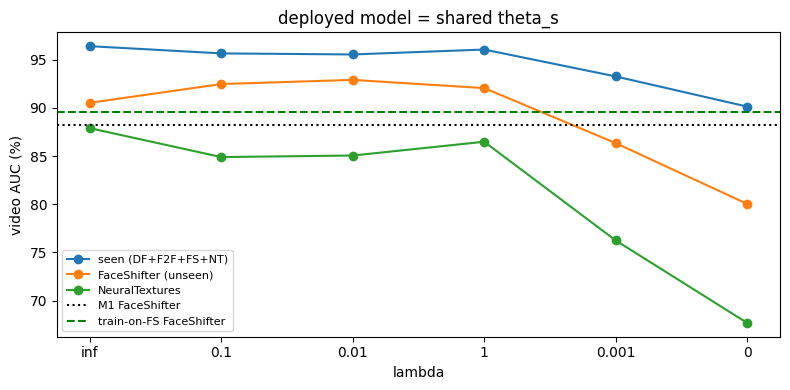

best FaceShifter: lambda 0.01 -> 92.91   (M1 88.19, train-on-FS 89.56)


In [13]:
# 5.2 GBLA vs lambda
rows = []
histories = {}
for lam in LAMBDAS:
    path = run_dir_for(lam) / "results.json"
    tag = lam_tag(lam)
    if not path.exists():
        print(f"lambda {tag}: not finished")
        continue
    res = json.loads(path.read_text())
    histories[tag] = res["history"]
    row = {"lambda": tag, **video_auc_from_records(res["test"])}
    row.update({f"|d| {k}": v for k, v in res.get("delta_norms", {}).items()})
    rows.append(row)
sweep = pd.DataFrame(rows).set_index("lambda")
display(sweep.round(2))
(M4_DIR / "sweep.csv").write_text(sweep.to_csv())

if len(sweep):
    fig, ax = plt.subplots(figsize=(8, 4))
    x = list(range(len(sweep)))
    ax.plot(x, sweep["seen"], marker="o", label="seen (DF+F2F+FS+NT)")
    ax.plot(x, sweep["FSh"], marker="o", label="FaceShifter (unseen)")
    ax.plot(x, sweep["NT"], marker="o", label="NeuralTextures")
    if "M1 pooled, epoch 10" in ref_table.index:
        ax.axhline(ref_table.loc["M1 pooled, epoch 10", "FSh"], color="black", linestyle=":", label="M1 FaceShifter")
    if "M3 train on FS" in ref_table.index:
        ax.axhline(ref_table.loc["M3 train on FS", "FSh"], color="green", linestyle="--", label="train-on-FS FaceShifter")
    ax.set_xticks(x, sweep.index)
    ax.set_xlabel("lambda")
    ax.set_ylabel("video AUC (%)")
    ax.set_title("deployed model = shared theta_s")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

best = sweep["FSh"].idxmax() if len(sweep) else None
if best is not None:
    base = ref_table.loc["M1 pooled, epoch 10", "FSh"] if "M1 pooled, epoch 10" in ref_table.index else float("nan")
    solo = ref_table.loc["M3 train on FS", "FSh"] if "M3 train on FS" in ref_table.index else float("nan")
    print(f"best FaceShifter: lambda {best} -> {sweep.loc[best, 'FSh']:.2f}   "
          f"(M1 {base:.2f}, train-on-FS {solo:.2f})")

### 5.3 Training curves

Left: validation video AUC of θ_s. Middle: training cross-entropy. Right: ‖δ_g‖ at the last epoch. A useful λ keeps seen AUC close to λ = ∞ while ‖δ‖ is clearly non-zero and FaceShifter is at least as high as M1.

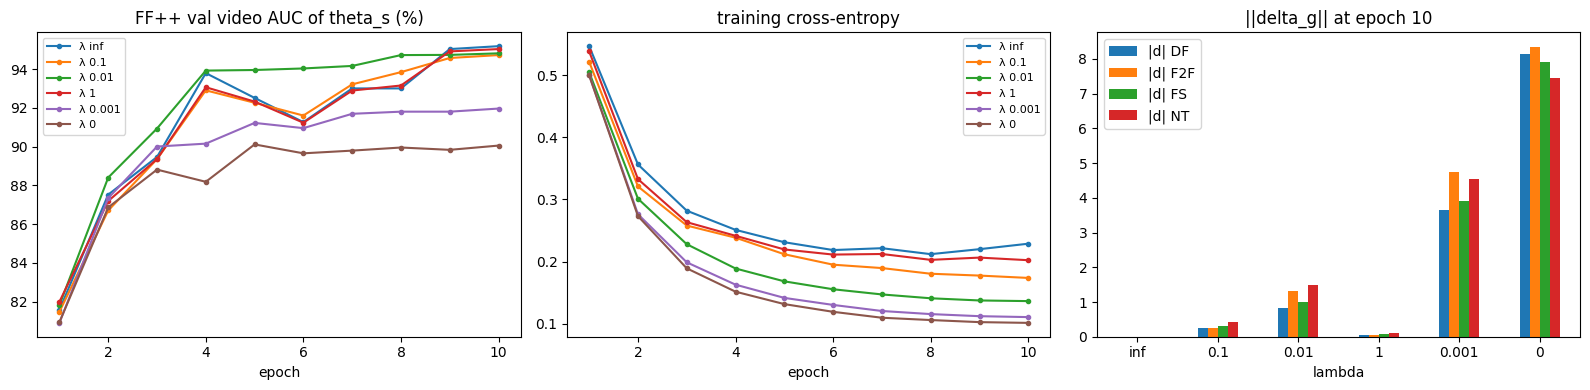

In [14]:
# 5.3 Training curves
assert histories, "no finished runs"
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for tag, hist in histories.items():
    h = pd.DataFrame(hist)
    axes[0].plot(h.epoch, h["val video AUC"], marker=".", label=f"λ {tag}")
    axes[1].plot(h.epoch, h["ce"], marker=".", label=f"λ {tag}")
axes[0].set_title("FF++ val video AUC of theta_s (%)")
axes[1].set_title("training cross-entropy")
for ax in axes[:2]:
    ax.set_xlabel("epoch")
    ax.legend(fontsize=8)

if len(sweep):
    delta_cols = [c for c in sweep.columns if c.startswith("|d|")]
    sweep[delta_cols].plot.bar(ax=axes[2], legend=True)
    axes[2].set_title("||delta_g|| at epoch 10")
    axes[2].tick_params(axis="x", labelrotation=0)
plt.tight_layout()
plt.show()

## 6. Send results back

1. Save this notebook (Ctrl+S) with outputs.
2. From the repository folder on C-DAC:

```bash
git pull
git add M4.ipynb
git commit -m "M4 GBLA lambda sweep"
git push
```

When git asks for a password, paste your GitHub token. Do not put the token in the notebook or any file, and do not send it to me.

**Order:** run all cells top to bottom. 4.2 must print `GBLA CHECKS OK` before 4.3. 4.3 resumes. If the job has few CPUs, loading the crops (2.2) is the slow part; training itself is about 1.3 h per λ. You can stop after λ = inf, 0.1 and 0.01 if time is short: those three already answer whether a private offset helps FaceShifter. Delete a run folder to redo that λ.

**What I need:** 4.2 checks, the epoch lines, the 5.2 table and figure.